# Eta 1.5 A/E WDM Top 10% Energy Pixels

This notebook uses the already generated `eta-1_5` WDM products and plots only the A/E WDM pixels whose energy is in the top 10% of each panel. Here energy means the saved off-source-normalized WDM power in `1e5_wdm_multires_maps.npz`.

The threshold is computed separately for each channel and WDM resolution over the plotted frequency band.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def find_eta_dir() -> Path:
    candidates = [
        Path.cwd() / "lisa_link_sim" / "eta-1_5",
        Path.cwd() / "eta-1_5",
        Path.cwd().parent / "eta-1_5",
        Path.cwd().parent / "lisa_link_sim" / "eta-1_5",
    ]
    for candidate in candidates:
        if (candidate / "outputs" / "1e5_wdm_multires_maps.npz").exists():
            return candidate.resolve()
    searched = "\n".join(str(path) for path in candidates)
    raise FileNotFoundError(f"Could not locate eta-1_5 generated WDM data. Searched:\n{searched}")


ETA_DIR = find_eta_dir()
OUTPUT_DIR = ETA_DIR / "outputs"
PLOT_DIR = OUTPUT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

MAPS_FILE = OUTPUT_DIR / "1e5_wdm_multires_maps.npz"
METADATA_FILE = OUTPUT_DIR / "1e5_plot_and_wdm_metadata.json"

metadata = json.loads(METADATA_FILE.read_text())
maps = np.load(MAPS_FILE, allow_pickle=False)

WDM_CONFIGS = metadata["wdm_configs"]
LOW_FREQ_CUT = float(metadata["low_freq_cut_hz"])
HIGH_FREQ_CUT = float(metadata["high_freq_cut_hz"])
SIGNAL_WINDOW_REL = maps["signal_window_rel"].astype(float)
SIGNAL_PEAK_REL = float(maps["signal_peak_rel"])

ETA_DIR, MAPS_FILE

(PosixPath('/Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/eta-1_5'),
 PosixPath('/Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/eta-1_5/outputs/1e5_wdm_multires_maps.npz'))

In [2]:
SOURCE = "noisy_AET"
CHANNELS = ["A", "E"]
TOP_FRACTION = 0.10
TOP_PERCENTILE = 100.0 * (1.0 - TOP_FRACTION)


def centers_to_edges(values: np.ndarray) -> np.ndarray:
    values = np.asarray(values, dtype=float)
    if values.size == 1:
        width = 1.0
        return np.array([values[0] - 0.5 * width, values[0] + 0.5 * width])
    edges = np.empty(values.size + 1, dtype=float)
    edges[1:-1] = 0.5 * (values[:-1] + values[1:])
    edges[0] = values[0] - 0.5 * (values[1] - values[0])
    edges[-1] = values[-1] + 0.5 * (values[-1] - values[-2])
    return np.maximum(edges, np.nextafter(0.0, 1.0))


def robust_limits(images: list[np.ndarray]) -> tuple[float, float]:
    finite = [image[np.isfinite(image)] for image in images if np.any(np.isfinite(image))]
    if not finite:
        return -1.0, 1.0
    vals = np.concatenate(finite)
    lo, hi = np.nanpercentile(vals, [2.0, 98.0])
    if not np.isfinite(lo) or not np.isfinite(hi) or lo == hi:
        lo = float(np.nanmin(vals))
        hi = float(np.nanmax(vals))
    return float(lo), float(hi)


def top_energy_panel(channel: str, resolution: str) -> dict[str, object]:
    prefix = f"{SOURCE}_{channel}_{resolution}"
    power = maps[f"{prefix}_normalized_power"].astype(float)
    times = maps[f"{prefix}_times_rel"].astype(float)
    freqs = maps[f"{prefix}_freqs_hz"].astype(float)

    freq_mask = (freqs >= LOW_FREQ_CUT) & (freqs <= HIGH_FREQ_CUT)
    band_power = power[freq_mask]
    band_freqs = freqs[freq_mask]

    finite = np.isfinite(band_power)
    if not np.any(finite):
        threshold = np.nan
        top_mask = finite
    else:
        threshold = float(np.nanpercentile(band_power[finite], TOP_PERCENTILE))
        top_mask = finite & (band_power >= threshold) & (band_power > 0.0)

    image = np.full(band_power.shape, np.nan, dtype=float)
    image[top_mask] = np.log10(band_power[top_mask])

    total_energy = float(np.nansum(band_power[finite])) if np.any(finite) else np.nan
    top_energy = float(np.nansum(band_power[top_mask])) if np.any(top_mask) else 0.0
    pixel_count = int(np.count_nonzero(finite))
    top_pixel_count = int(np.count_nonzero(top_mask))

    return {
        "times": times,
        "freqs": band_freqs,
        "image": image,
        "threshold": threshold,
        "pixel_count": pixel_count,
        "top_pixel_count": top_pixel_count,
        "top_pixel_fraction": top_pixel_count / pixel_count if pixel_count else np.nan,
        "top_energy_fraction": top_energy / total_energy if total_energy > 0 else np.nan,
        "max_energy": float(np.nanmax(band_power[finite])) if np.any(finite) else np.nan,
    }

In [3]:
panels: dict[tuple[int, int], dict[str, object]] = {}
rows: list[dict[str, float | int | str]] = []
images: list[np.ndarray] = []

for row_idx, config in enumerate(WDM_CONFIGS):
    resolution = config["label"]
    for col_idx, channel in enumerate(CHANNELS):
        panel = top_energy_panel(channel, resolution)
        panels[(row_idx, col_idx)] = panel
        images.append(panel["image"])
        rows.append(
            {
                "source": SOURCE,
                "channel": channel,
                "resolution": resolution,
                "target_dt_s": float(config["target_dt"]),
                "wdm_M": int(config["M"]),
                "top_percentile_threshold": TOP_PERCENTILE,
                "energy_threshold": float(panel["threshold"]),
                "max_energy": float(panel["max_energy"]),
                "pixel_count": int(panel["pixel_count"]),
                "top_pixel_count": int(panel["top_pixel_count"]),
                "top_pixel_fraction": float(panel["top_pixel_fraction"]),
                "top_energy_fraction": float(panel["top_energy_fraction"]),
            }
        )

stats_df = pd.DataFrame(rows)
stats_file = OUTPUT_DIR / "1e5_wdm_AE_top10_energy_pixels_stats.csv"
stats_df.to_csv(stats_file, index=False)
display(stats_df)
print(f"saved {stats_file}")

,source,channel,resolution,target_dt_s,wdm_M,top_percentile_threshold,energy_threshold,max_energy,pixel_count,top_pixel_count,top_pixel_fraction,top_energy_fraction
0,noisy_AET,A,dt1_M128,1.0,128,90.0,3.806953,615.859375,29300,2930,0.100000,0.460733
1,noisy_AET,E,dt1_M128,1.0,128,90.0,3.807135,492.372894,29300,2930,0.100000,0.418007
2,noisy_AET,A,dt1_M256,1.0,256,90.0,3.813910,712.821045,29886,2989,0.100013,0.477848
3,noisy_AET,E,dt1_M256,1.0,256,90.0,3.778530,475.668884,29886,2989,0.100013,0.429269
4,noisy_AET,A,dt1_M512,1.0,512,90.0,3.848528,702.808472,29886,2989,0.100013,0.449988
5,noisy_AET,E,dt1_M512,1.0,512,90.0,3.745439,504.441406,29886,2989,0.100013,0.404428
6,noisy_AET,A,dt1_M1024,1.0,1024,90.0,3.824358,397.359589,29988,2999,0.100007,0.412018
7,noisy_AET,E,dt1_M1024,1.0,1024,90.0,3.769045,159.256180,29988,2999,0.100007,0.377184
8,noisy_AET,A,dt2_M2048,2.0,2048,90.0,3.744396,706.934875,30303,3031,0.100023,0.500262
9,noisy_AET,E,dt2_M2048,2.0,2048,90.0,3.761632,232.770401,30303,3031,0.100023,0.432390


saved /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/eta-1_5/outputs/1e5_wdm_AE_top10_energy_pixels_stats.csv


saved /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/eta-1_5/outputs/plots/13_eta_1_5_wdm_AE_top10_energy_pixels.png


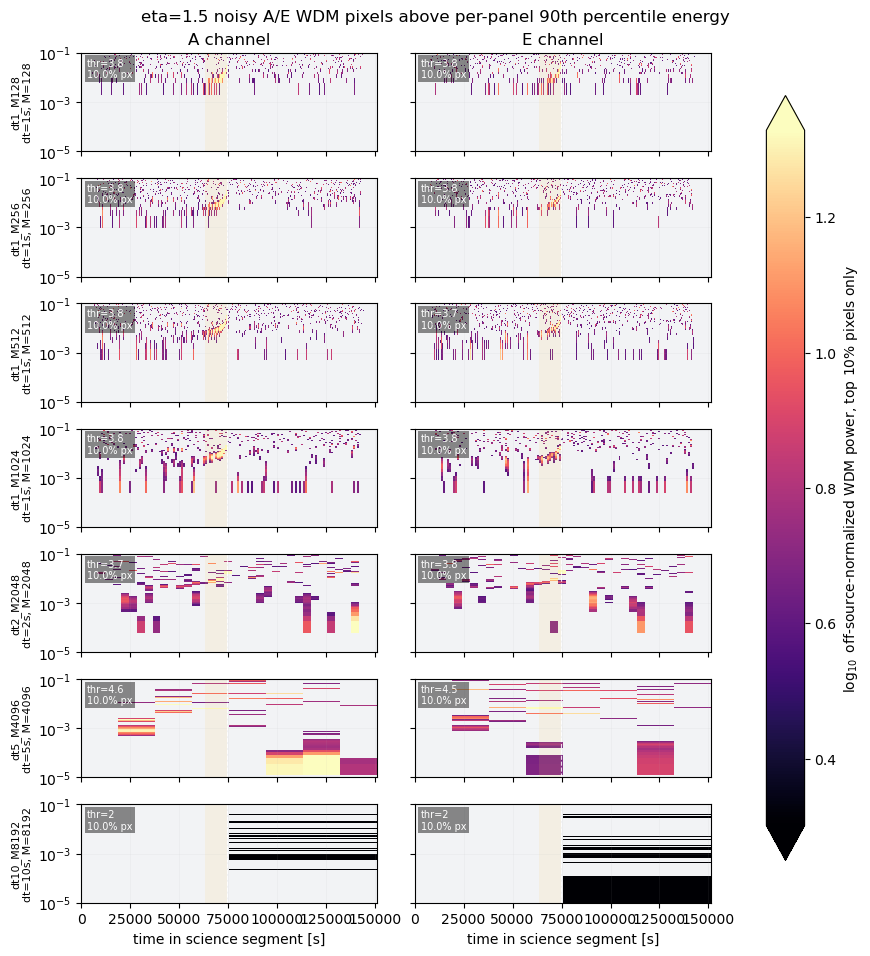

saved /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/eta-1_5/outputs/plots/13_eta_1_5_wdm_AE_top10_energy_pixels_no_highlight.png


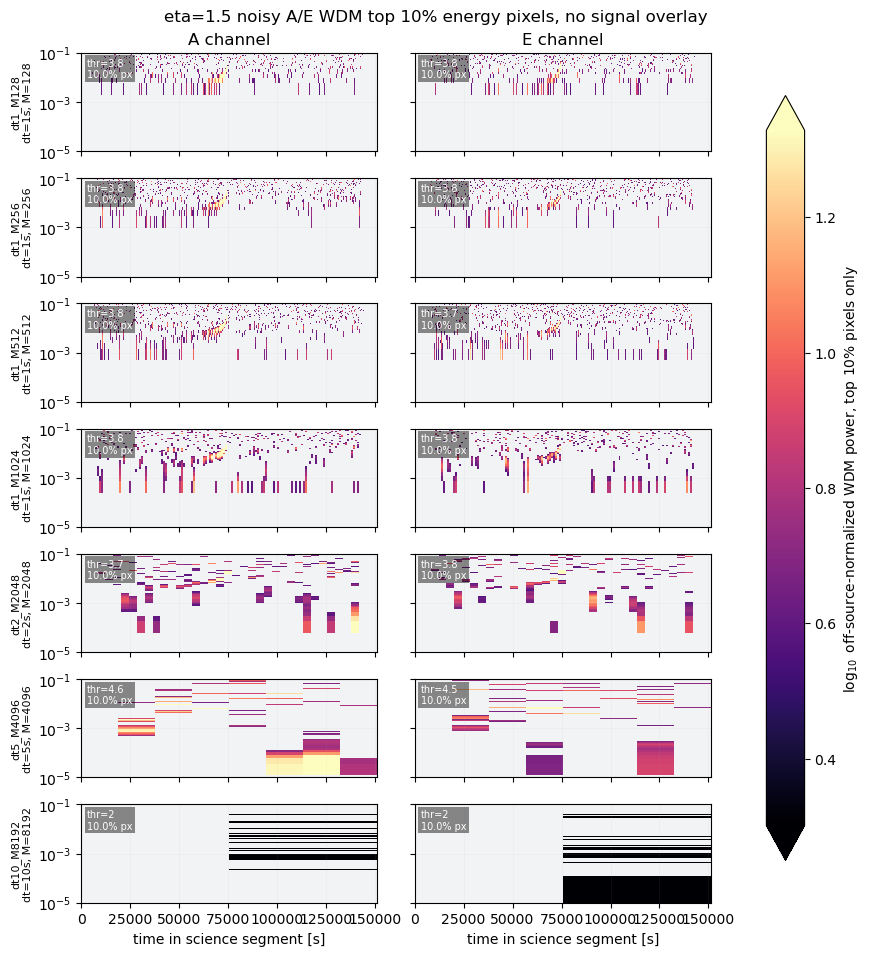

saved /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/eta-1_5/outputs/plots/13_eta_1_5_wdm_AE_top10_energy_pixels_signal_zoom.png


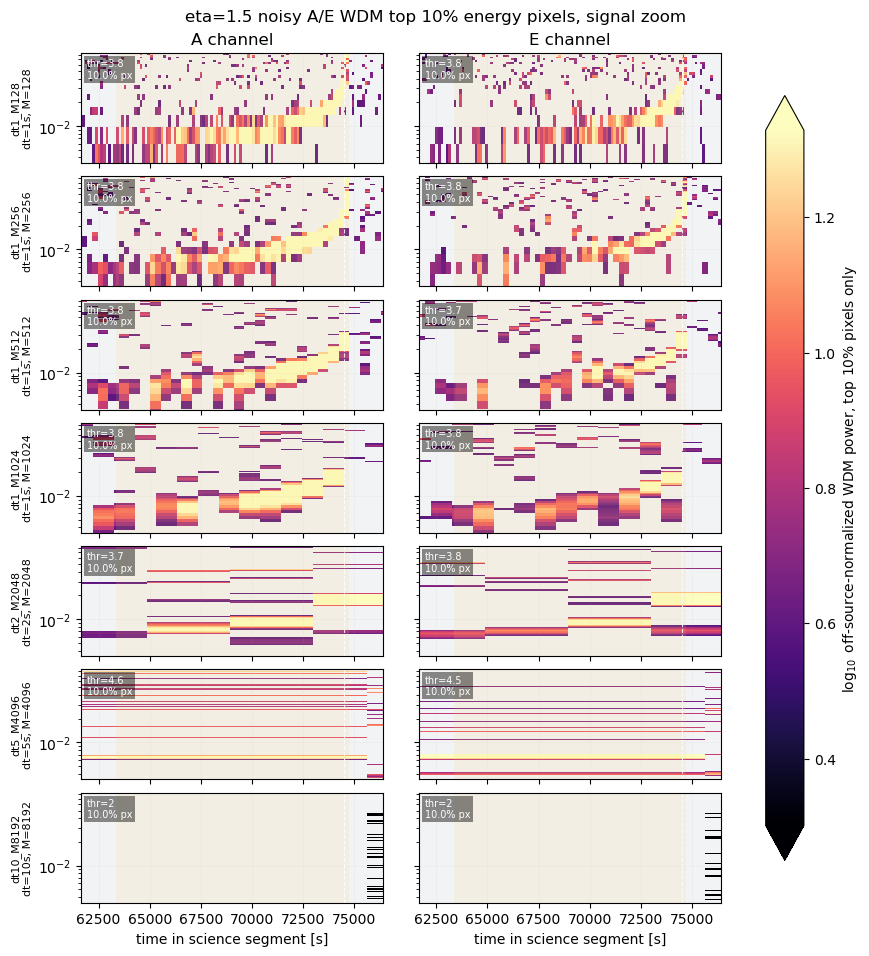

saved /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/eta-1_5/outputs/plots/13_eta_1_5_wdm_AE_top10_energy_pixels_signal_zoom_no_highlight.png


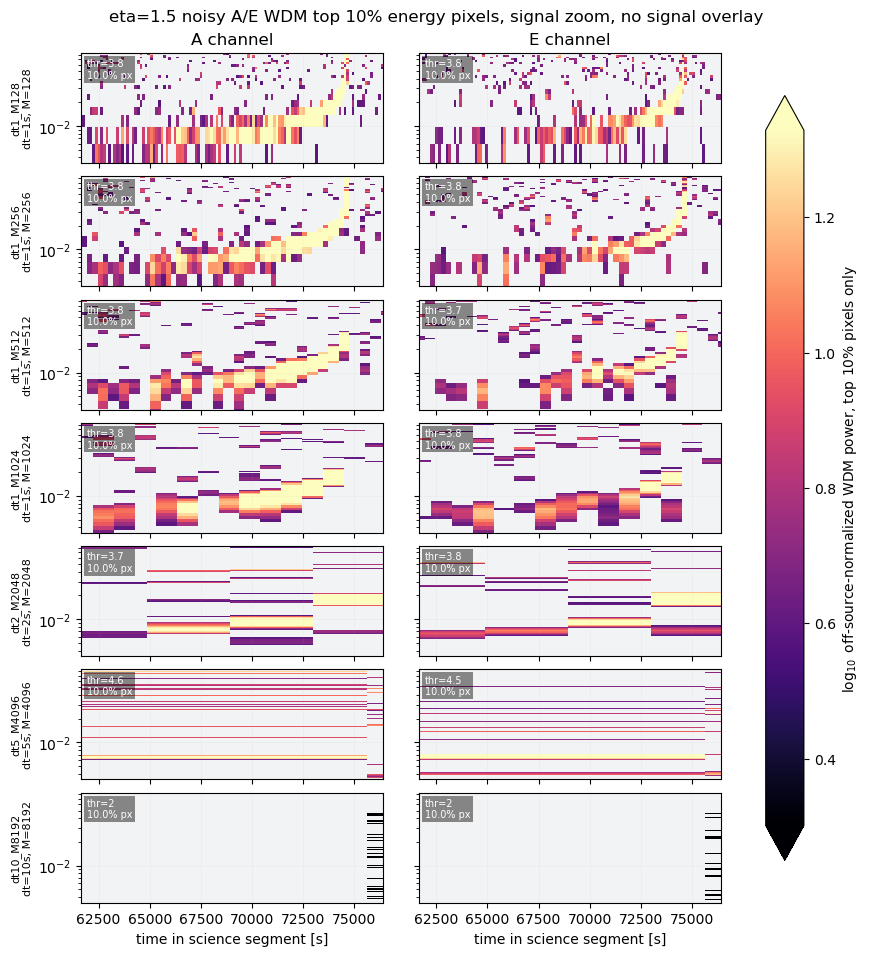

signal zoom time range: 61641.7 to 76424.4 s
signal zoom frequency range: 0.0034 to 0.0844 Hz


In [4]:
def signal_frequency_limits(percentile: float = 98.0) -> tuple[float, float]:
    bounds: list[float] = []
    for config in WDM_CONFIGS:
        resolution = config["label"]
        for channel in CHANNELS:
            prefix = f"gw_only_AET_{channel}_{resolution}"
            power_key = f"{prefix}_normalized_power"
            if power_key not in maps:
                continue
            power = maps[power_key].astype(float)
            times = maps[f"{prefix}_times_rel"].astype(float)
            freqs = maps[f"{prefix}_freqs_hz"].astype(float)
            freq_mask = (freqs >= LOW_FREQ_CUT) & (freqs <= HIGH_FREQ_CUT)
            time_mask = (times >= SIGNAL_WINDOW_REL[0]) & (times <= SIGNAL_WINDOW_REL[1])
            band = power[np.ix_(freq_mask, time_mask)]
            band_freqs = freqs[freq_mask]
            finite = np.isfinite(band) & (band > 0.0)
            if band.size == 0 or not np.any(finite):
                continue
            threshold = np.nanpercentile(band[finite], percentile)
            freq_has_signal = np.any(finite & (band >= threshold), axis=1)
            if np.any(freq_has_signal):
                bounds.extend([float(np.min(band_freqs[freq_has_signal])), float(np.max(band_freqs[freq_has_signal]))])

    if not bounds:
        return LOW_FREQ_CUT, HIGH_FREQ_CUT
    return max(LOW_FREQ_CUT, min(bounds) * 0.6), min(HIGH_FREQ_CUT, max(bounds) * 1.8)


def plot_top_energy_pixels(
    plot_file: Path,
    title: str,
    *,
    show_signal_overlay: bool,
    xlim: tuple[float, float] | None = None,
    ylim: tuple[float, float] = (LOW_FREQ_CUT, HIGH_FREQ_CUT),
    dpi: int = 180,
) -> Path:
    cmap = plt.get_cmap("magma").copy()
    cmap.set_bad((1.0, 1.0, 1.0, 0.0))

    fig, axes = plt.subplots(
        len(WDM_CONFIGS),
        len(CHANNELS),
        figsize=(8.6, max(1.35 * len(WDM_CONFIGS), 8.8)),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )
    axes = np.asarray(axes).reshape(len(WDM_CONFIGS), len(CHANNELS))
    last_im = None

    for row_idx, config in enumerate(WDM_CONFIGS):
        resolution = config["label"]
        for col_idx, channel in enumerate(CHANNELS):
            ax = axes[row_idx, col_idx]
            ax.set_facecolor("#f2f3f5")
            panel = panels[(row_idx, col_idx)]
            image = np.ma.masked_invalid(panel["image"])
            last_im = ax.pcolormesh(
                centers_to_edges(panel["times"]),
                centers_to_edges(panel["freqs"]),
                image,
                shading="auto",
                cmap=cmap,
                vmin=vmin,
                vmax=vmax,
            )
            if show_signal_overlay:
                ax.axvspan(SIGNAL_WINDOW_REL[0], SIGNAL_WINDOW_REL[1], color="#ffd166", alpha=0.12, lw=0)
                ax.axvline(SIGNAL_PEAK_REL, color="white", ls="--", lw=0.8, alpha=0.85)
            ax.set_yscale("log")
            ax.set_ylim(*ylim)
            if xlim is not None:
                ax.set_xlim(*xlim)
            ax.grid(alpha=0.14, lw=0.4)
            ax.text(
                0.02,
                0.95,
                f"thr={panel['threshold']:.2g}\n{panel['top_pixel_fraction']:.1%} px",
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=7,
                color="white",
                bbox={"facecolor": "black", "alpha": 0.45, "edgecolor": "none", "pad": 1.8},
            )
            if row_idx == 0:
                ax.set_title(f"{channel} channel")
            if col_idx == 0:
                ax.set_ylabel(f"{resolution}\ndt={config['target_dt']:g}s, M={config['M']}", fontsize=8)
            else:
                ax.tick_params(labelleft=False)
            if row_idx == len(WDM_CONFIGS) - 1:
                ax.set_xlabel("time in science segment [s]")
            else:
                ax.tick_params(labelbottom=False)

    if last_im is not None:
        cbar = fig.colorbar(last_im, ax=axes, shrink=0.9, extend="both")
        cbar.set_label(r"$\log_{10}$ off-source-normalized WDM power, top 10% pixels only")

    fig.suptitle(title, fontsize=12)
    fig.savefig(plot_file, dpi=dpi)
    print(f"saved {plot_file}")
    plt.show()
    return plot_file


vmin, vmax = robust_limits(images)

full_with_highlight_file = PLOT_DIR / "13_eta_1_5_wdm_AE_top10_energy_pixels.png"
plot_top_energy_pixels(
    full_with_highlight_file,
    "eta=1.5 noisy A/E WDM pixels above per-panel 90th percentile energy",
    show_signal_overlay=True,
)

full_no_highlight_file = PLOT_DIR / "13_eta_1_5_wdm_AE_top10_energy_pixels_no_highlight.png"
plot_top_energy_pixels(
    full_no_highlight_file,
    "eta=1.5 noisy A/E WDM top 10% energy pixels, no signal overlay",
    show_signal_overlay=False,
)

signal_width = float(SIGNAL_WINDOW_REL[1] - SIGNAL_WINDOW_REL[0])
time_padding = 0.15 * signal_width
signal_zoom_xlim = (max(0.0, SIGNAL_WINDOW_REL[0] - time_padding), SIGNAL_WINDOW_REL[1] + time_padding)
signal_zoom_ylim = signal_frequency_limits(percentile=98.0)

signal_zoom_file = PLOT_DIR / "13_eta_1_5_wdm_AE_top10_energy_pixels_signal_zoom.png"
plot_top_energy_pixels(
    signal_zoom_file,
    "eta=1.5 noisy A/E WDM top 10% energy pixels, signal zoom",
    show_signal_overlay=True,
    xlim=signal_zoom_xlim,
    ylim=signal_zoom_ylim,
    dpi=200,
)

signal_zoom_no_highlight_file = PLOT_DIR / "13_eta_1_5_wdm_AE_top10_energy_pixels_signal_zoom_no_highlight.png"
plot_top_energy_pixels(
    signal_zoom_no_highlight_file,
    "eta=1.5 noisy A/E WDM top 10% energy pixels, signal zoom, no signal overlay",
    show_signal_overlay=False,
    xlim=signal_zoom_xlim,
    ylim=signal_zoom_ylim,
    dpi=200,
)

print(f"signal zoom time range: {signal_zoom_xlim[0]:.1f} to {signal_zoom_xlim[1]:.1f} s")
print(f"signal zoom frequency range: {signal_zoom_ylim[0]:.3g} to {signal_zoom_ylim[1]:.3g} Hz")

The saved PNGs and CSV are written into the existing `eta-1_5/outputs` tree so these diagnostics stay next to the generated data they use. The zoom panel uses the signal window with 15% time padding and a frequency range inferred from the high-energy GW-only A/E pixels inside that window.